In [5]:
# 1. 기존 패키지들을 완전히 지웁니다.
%pip uninstall -y google-cloud-aiplatform google-cloud-vertexai

# 2. 캐시를 무시하고 두 패키지를 한 번에 최신 버전으로 재설치합니다.
%pip install --no-cache-dir --upgrade google-cloud-aiplatform google-cloud-vertexai

Found existing installation: google-cloud-aiplatform 1.153.1
Uninstalling google-cloud-aiplatform-1.153.1:
  Successfully uninstalled google-cloud-aiplatform-1.153.1
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 125.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [google-cloud-aiplatform]-cloud-aiplatform]
Note: you may need to restart the kernel to use updated packages.


In [6]:
import IPython

app = IPython.Application.instance()
app.kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

In [ ]:
import os
import cv2
import json
import matplotlib.pyplot as plt
import vertexai
from vertexai.generative_models import GenerativeModel, Part, Image
from ultralytics import YOLO
from roboflow import Roboflow

# ==========================================
# 1. Configuration & Initialization
# ==========================================
ROBOFLOW_API_KEY = "YOUR_ROBOFLOW_KEY"
GCP_PROJECT_ID = "duyuthon"  # 본인의 GCP 프로젝트 ID
gemini_model = GenerativeModel("gemini-2.5-flash")

# ==========================================
# 2. Training Pipeline (Epochs 75, New AC Dataset)
# ==========================================
def train_models():
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    
    print("--- Starting Student Detection Model Training ---")
    student_project = rf.workspace("amine-dnsi2").project("classroom-sjp9h").version(1)
    student_dataset = student_project.download("yolov8")
    
    model_student = YOLO("yolov8n.pt")
    # [수정 1] epochs를 75로 상향
    model_student.train(data=f"{student_dataset.location}/data.yaml", epochs=75, imgsz=640, project="campus", name="student_model", device="cpu")

    print("--- Starting Air Conditioner Model Training ---")
    ac_project = rf.workspace("4-52p2c").project("office-air-condition").version(1)
    ac_dataset = ac_project.download("yolov8")
    
    model_ac = YOLO("yolov8n.pt")
    model_ac.train(data=f"{ac_dataset.location}/data.yaml", epochs=100, imgsz=640, project="campus", name="ac_model", device="cpu")
    
    print("Training Complete! Remember to STOP the VM instance to avoid charges.")

# ==========================================
# 3. Gemini Analysis Function
# ==========================================
def check_status_with_gemini(original_img_path, crop_img_path):
    original_img = Image.load_from_file(original_img_path)
    crop_img = Image.load_from_file(crop_img_path)
    
    original_part = Part.from_image(original_img)
    crop_part = Part.from_image(crop_img)
    
    prompt = """
    You are a building energy management AI.
    The first image is the original full photo of a classroom. 
    The second image is a cropped close-up of a ceiling 4-way air conditioner.
    Analyze the following two power states:

    1. "ac_status": Look at the second image (AC). If the louvers (blades) are open or the operation LED is on, return "ON". If they are closed and inactive, return "OFF".
    2. "light_status": Look at the background of the first image (original). If the ceiling indoor lights (fluorescent/LED) are turned on and emitting light, return "ON". If they are turned off, return "OFF".

    Respond STRICTLY in the following JSON format only without any markdown formatting:
    {
        "ac_status": "ON or OFF",
        "light_status": "ON or OFF",
        "reason": "Your detailed reasoning"
    }
    """
    response = gemini_model.generate_content([original_part, crop_part, prompt])
    return response.text

# ==========================================
# 4. Inference & Visualization Pipeline
# ==========================================
def analyze_classroom_image(image_path, student_model_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    student_model = YOLO(student_model_path)
    ac_model = YOLO(ac_model_path)
    
    # ---------------------------------------------------------
    # Step 1: Detect Students (with Debug Visualization)
    # ---------------------------------------------------------
    # [수정 4] confidence 0.4 이상만 탐지
    student_results = student_model(image_path, conf=0.4)[0]
    
    # [수정 3] 학생 탐지 결과 화면 출력
    annotated_student_img = student_results.plot()
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated_student_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Student Detection (Found: {len(student_results.boxes)})")
    plt.axis('off')
    plt.show()

    student_count = len(student_results.boxes)
    if student_count > 0:
        return {"result": "PASS", "message": "Students are present in the classroom. Status normal."}
    
    print("Classroom is empty. Checking for energy waste (AC and Lights)...")
    
    # ---------------------------------------------------------
    # Step 2: Detect AC (with Debug Visualization)
    # ---------------------------------------------------------
    # [수정 4] confidence 0.4 이상만 탐지
    ac_results = ac_model(image_path, conf=0.4)[0]
    
    annotated_ac_img = ac_results.plot()
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated_ac_img, cv2.COLOR_BGR2RGB))
    plt.title(f"AC Detection (Found: {len(ac_results.boxes)})")
    plt.axis('off')
    plt.show()
    
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image (Confidence < 0.4)."}
    
    # ---------------------------------------------------------
    # Step 3: Crop AC and Request Gemini Analysis
    # ---------------------------------------------------------
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[y1:y2, x1:x2] 
        
        # 크롭된 에어컨 이미지 확인
        plt.figure(figsize=(3, 3))
        plt.imshow(cv2.cvtColor(ac_crop, cv2.COLOR_BGR2RGB))
        plt.title(f"Cropped AC #{i+1}")
        plt.axis('off')
        plt.show()
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print(f"Sending Cropped AC #{i+1} to Gemini 2.5 Flash...")
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        os.remove(temp_crop_path)
        
        try:
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected in an empty classroom!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "Classroom is empty and all power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Failed to parse Gemini response: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    train_models()
    print("train finished.")
    """
    # 추론 테스트 코드 (학습이 완료된 후 사용)
    test_image = "test_again.png" 
    
    # 파일이 존재하는지 먼저 확인
    if not os.path.exists(test_image):
        print(f"Error: {test_image} 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
    else:
        result = analyze_classroom_image(
            image_path=test_image, 
            student_model_path="runs/detect/campus/student_model/weights/best.pt", # 실제 학습된 파일 경로로 맞춰주세요.
            ac_model_path="runs/detect/campus/ac_model/weights/best.pt"            # 실제 학습된 파일 경로로 맞춰주세요.
        )
        print("\n--- Final Analysis Result ---")
        print(json.dumps(result, indent=4, ensure_ascii=False))
    """

/opt/micromamba/envs/jupyterlab/lib/python3.12/site-packages/google/cloud/aiplatform/models.py:52: FutureWarning: Support for google-cloud-storage < 3.0.0 will be removed in a future version of google-cloud-aiplatform. Please upgrade to google-cloud-storage >= 3.0.0.
  from google.cloud.aiplatform.utils import gcs_utils
This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.


--- Starting Student Detection Model Training ---
loading Roboflow workspace...
loading Roboflow project...
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.12.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jupyter/classroom-1/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=75, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_sc

KeyboardInterrupt: 


--- [Analysis Started] t7.jpg ---

image 1/1 /home/jupyter/t7.jpg: 480x640 3 persons, 67.5ms
Speed: 3.5ms preprocess, 67.5ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


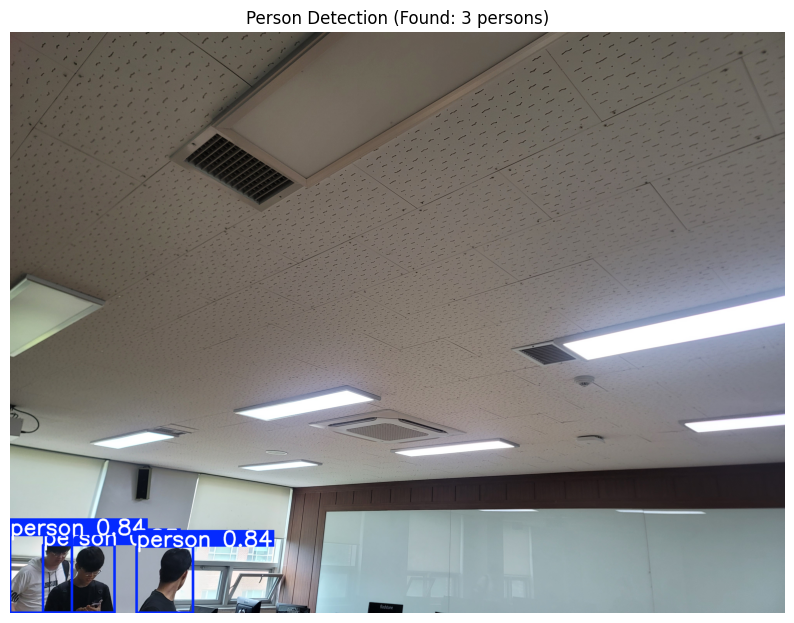

3 Persons are present in the classroom.
Classroom is empty. Checking for energy waste (AC and Lights)...

image 1/1 /home/jupyter/t7.jpg: 480x640 (no detections), 61.0ms
Speed: 3.1ms preprocess, 61.0ms inference, 0.6ms postprocess per image at shape (1, 3, 480, 640)


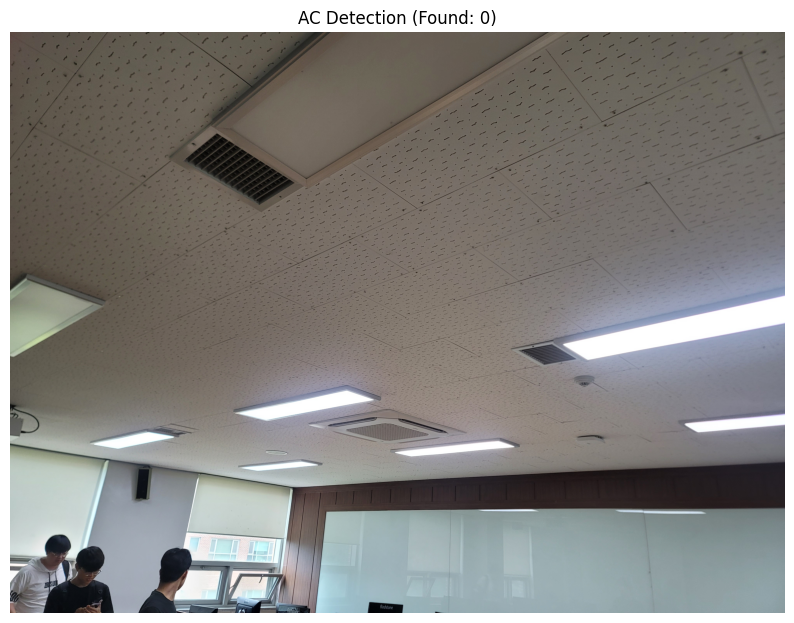


--- Final Analysis Result ---
{
    "result": "ERROR",
    "message": "Air conditioner not found in the image (Confidence < 0.4)."
}


In [ ]:
import os
import cv2
import json
import matplotlib.pyplot as plt
import vertexai
from vertexai.generative_models import GenerativeModel, Part, Image
from ultralytics import YOLO
from roboflow import Roboflow

# ==========================================
# 1. Configuration & Initialization
# ==========================================
ROBOFLOW_API_KEY = "YOUR_ROBOFLOW_KEY"
GCP_PROJECT_ID = "duyuthon"  # 본인의 GCP 프로젝트 ID
gemini_model = GenerativeModel("gemini-2.5-flash")

# ==========================================
# 3. Gemini Analysis Function
# ==========================================
def check_status_with_gemini(original_img_path, crop_img_path):
    original_img = Image.load_from_file(original_img_path)
    crop_img = Image.load_from_file(crop_img_path)
    
    original_part = Part.from_image(original_img)
    crop_part = Part.from_image(crop_img)
    
    prompt = """
    You are a building energy management AI.
    The first image is the original full photo of a classroom. 
    The second image is a cropped close-up of a ceiling 4-way air conditioner.
    Analyze the following two power states:

    1. "ac_status": Look at the second image (AC). If the louvers (blades) are open or the operation LED is on, return "ON". If they are closed and inactive, return "OFF".
    2. "light_status": Look at the background of the first image (original). If the ceiling indoor lights (fluorescent/LED) are turned on and emitting light, return "ON". If they are turned off, return "OFF".

    Respond STRICTLY in the following JSON format only without any markdown formatting:
    {
        "ac_status": "ON or OFF",
        "light_status": "ON or OFF",
        "reason": "Your detailed reasoning"
    }
    """
    response = gemini_model.generate_content([original_part, crop_part, prompt])
    return response.text

# ==========================================
# 4. Inference & Visualization Pipeline
# ==========================================
def analyze_classroom_image(image_path, ac_model_path):
    print(f"\n--- [Analysis Started] {image_path} ---")
    
    # Pre-trained base YOLOv8 model for person detection
    person_model = YOLO("yolov8n.pt") 
    ac_model = YOLO(ac_model_path)
    
    # ---------------------------------------------------------
    # Step 1: Detect Person (Using COCO base model, class 0 is 'person')
    # ---------------------------------------------------------
    # classes=[0]을 추가하여 '사람'만 감지하도록 강제합니다. (책상, 의자 등 무시)
    person_results = person_model(image_path, conf=0.4, classes=[0])[0]
    
    annotated_person_img = person_results.plot()
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated_person_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Person Detection (Found: {len(person_results.boxes)} persons)")
    plt.axis('off')
    plt.show()

    person_count = len(person_results.boxes)
    #if person_count > 0:
    #    return {"result": "PASS", "message": f"{person_count} Persons are present in the classroom. Status normal."}
    print(f"{person_count} Persons are present in the classroom.")
    print("Classroom is empty. Checking for energy waste (AC and Lights)...")
    
    # ---------------------------------------------------------
    # Step 2: Detect AC (with Debug Visualization)
    # ---------------------------------------------------------
    ac_results = ac_model(image_path, conf=0.4)[0]
    
    annotated_ac_img = ac_results.plot()
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated_ac_img, cv2.COLOR_BGR2RGB))
    plt.title(f"AC Detection (Found: {len(ac_results.boxes)})")
    plt.axis('off')
    plt.show()
    
    if len(ac_results.boxes) == 0:
        return {"result": "ERROR", "message": "Air conditioner not found in the image (Confidence < 0.4)."}
    
    # ---------------------------------------------------------
    # Step 3: Crop AC and Request Gemini Analysis
    # ---------------------------------------------------------
    img = cv2.imread(image_path)
    for i, box in enumerate(ac_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        ac_crop = img[y1:y2, x1:x2] 
        
        plt.figure(figsize=(3, 3))
        plt.imshow(cv2.cvtColor(ac_crop, cv2.COLOR_BGR2RGB))
        plt.title(f"Cropped AC #{i+1}")
        plt.axis('off')
        plt.show()
        
        temp_crop_path = f"temp_ac_crop_{i}.jpg"
        cv2.imwrite(temp_crop_path, ac_crop)
        
        print(f"Sending Cropped AC #{i+1} to Gemini 2.5 Flash...")
        ai_response = check_status_with_gemini(image_path, temp_crop_path)
        os.remove(temp_crop_path)
        
        try:
            clean_json_str = ai_response.strip().strip("```json").strip("```").strip()
            status_data = json.loads(clean_json_str)
            
            ac_on = (status_data.get("ac_status") == "ON")
            light_on = (status_data.get("light_status") == "ON")
            
            if ac_on or light_on:
                return {
                    "result": "WASTE_DETECTED",
                    "message": "Energy waste detected in an empty classroom!",
                    "ac_status": status_data.get("ac_status"),
                    "light_status": status_data.get("light_status"),
                    "reason": status_data.get("reason")
                }
            else:
                return {"result": "PASS", "message": "Classroom is empty and all power sources are OFF."}
                
        except json.JSONDecodeError:
            return {"result": "ERROR", "message": f"Failed to parse Gemini response: {ai_response}"}

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    test_image = "t8.jpg" 
    
    if not os.path.exists(test_image):
        print(f"Error: {test_image} 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
    else:
        result = analyze_classroom_image(
            image_path=test_image, 
            # 학생 모델 경로는 사라졌으므로, 에어컨 모델 경로만 전달합니다.
            ac_model_path="runs/detect/campus/ac_model/weights/best.pt" 
        )
        print("\n--- Final Analysis Result ---")
        print(json.dumps(result, indent=4, ensure_ascii=False))
